# EDA Deskriptif sMRI T1-weighted ABIDE I

Notebook ini melakukan inspeksi dan EDA deskriptif terhadap file NIfTI `.nii.gz`. Tidak ada preprocessing, cleaning permanen, skull-stripping, normalisasi, matching final dengan CSV fenotipik, atau pemodelan.

Seluruh tabel dan grafik hanya ditampilkan pada output notebook. Notebook ini tidak membuat folder, CSV, atau PNG tambahan.

## 1. Setup dan konfigurasi

Ubah `SMRI_DIR` jika dataset dipindahkan. `nibabel` diperlukan untuk membaca header dan volume NIfTI. Jika belum tersedia, instalasi dapat dilakukan di Colab dengan `!pip install nibabel` pada cell terpisah.

In [9]:
from pathlib import Path
import re
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

try:
    import nibabel as nib
except ImportError as error:
    raise ImportError(
        "Paket nibabel belum tersedia. Jalankan `pip install nibabel`, "
        "lalu ulangi notebook."
    ) from error

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
sns.set_theme(style="whitegrid", context="notebook")

SMRI_DIR = Path(r"C:\Users\Lenovo\OneDrive\Documents\TUGAS AKHIR\dataset\all_anat_T1w")
FILE_PATTERN = "*.nii.gz"
MAX_FULL_LOAD_MB = 512
INTENSITY_SAMPLE_SIZE = 250_000
RANDOM_STATE = 42

print(f"Folder citra: {SMRI_DIR}")
if not SMRI_DIR.is_dir():
    raise FileNotFoundError(f"Folder citra tidak ditemukan: {SMRI_DIR}")
print("EDA ini hanya menampilkan hasil di notebook; tidak ada file output yang dibuat.")

Folder citra: C:\Users\Lenovo\OneDrive\Documents\TUGAS AKHIR\dataset\all_anat_T1w
EDA ini hanya menampilkan hasil di notebook; tidak ada file output yang dibuat.


## 2. Fungsi bantu

Fungsi berikut digunakan untuk inventarisasi, pembacaan metadata, statistik intensitas berbasis sampling, dan visualisasi. Flag QC hanya dicatat sebagai informasi; file tidak dihapus atau diubah.

In [10]:
SUBJECT_PATTERN = re.compile(r"(sub-[A-Za-z0-9]+)", re.IGNORECASE)

def subject_id_from_name(path):
    match = SUBJECT_PATTERN.search(path.name)
    return match.group(1) if match else np.nan

def finite_values(data):
    values = np.asarray(data)
    return values[np.isfinite(values)]

def intensity_statistics(image, sample_size=INTENSITY_SAMPLE_SIZE):
    """Hitung statistik intensitas; sampling dipakai bila volume sangat besar."""
    shape = tuple(image.shape[:3])
    voxel_count = int(np.prod(shape))
    data = np.asanyarray(image.dataobj).reshape(-1)
    if voxel_count > sample_size:
        rng = np.random.default_rng(RANDOM_STATE)
        indices = rng.choice(voxel_count, size=sample_size, replace=False)
        values = np.asarray(data[indices], dtype=np.float64)
        sampling = "random_sample"
    else:
        values = np.asarray(data, dtype=np.float64)
        sampling = "full_volume"
    finite = values[np.isfinite(values)]
    if finite.size == 0:
        return {"sampling": sampling, "sample_count": 0, "finite_count": 0,
                "min": np.nan, "max": np.nan, "mean": np.nan,
                "median": np.nan, "std": np.nan, "p01": np.nan,
                "p05": np.nan, "p25": np.nan, "p75": np.nan,
                "p95": np.nan, "p99": np.nan}
    percentiles = np.percentile(finite, [1, 5, 25, 50, 75, 95, 99])
    return {"sampling": sampling, "sample_count": int(values.size),
            "finite_count": int(finite.size), "min": float(finite.min()),
            "max": float(finite.max()), "mean": float(finite.mean()),
            "median": float(percentiles[3]), "std": float(finite.std()),
            "p01": float(percentiles[0]), "p05": float(percentiles[1]),
            "p25": float(percentiles[2]), "p75": float(percentiles[4]),
            "p95": float(percentiles[5]), "p99": float(percentiles[6])}

def inspect_nifti(path):
    result = {"file_name": path.name, "subject_id": subject_id_from_name(path),
              "read_ok": False, "error": "", "shape": np.nan,
              "ndim": np.nan, "voxel_spacing": np.nan, "orientation": np.nan,
              "affine": np.nan, "dtype": np.nan, "voxel_count": np.nan,
              "zero_voxel_count": np.nan, "nonzero_voxel_count": np.nan,
              "nonfinite_voxel_count": np.nan, "zero_fraction": np.nan}
    try:
        image = nib.load(str(path), mmap=True)
        data_shape = tuple(image.shape)
        spatial_shape = data_shape[:3]
        data = np.asanyarray(image.dataobj).reshape(-1)
        finite_mask = np.isfinite(data)
        zero_count = int(np.count_nonzero(data[finite_mask] == 0))
        nonzero_count = int(np.count_nonzero(data[finite_mask] != 0))
        voxel_count = int(data.size)
        result.update({"read_ok": True, "shape": str(data_shape), "ndim": len(data_shape),
                       "voxel_spacing": str(tuple(np.round(image.header.get_zooms()[:3], 5))),
                       "orientation": "-".join(nib.aff2axcodes(image.affine)),
                       "affine": np.array2string(image.affine, precision=3),
                       "dtype": str(image.get_data_dtype()), "voxel_count": voxel_count,
                       "zero_voxel_count": zero_count, "nonzero_voxel_count": nonzero_count,
                       "nonfinite_voxel_count": int((~finite_mask).sum()),
                       "zero_fraction": zero_count / voxel_count if voxel_count else np.nan})
        return result, image
    except Exception as error:
        result["error"] = f"{type(error).__name__}: {error}"
        return result, None

def show_three_views(image, title, percentile_clip=(1, 99)):
    data = np.asarray(image.get_fdata(dtype=np.float32))
    finite = np.isfinite(data)
    if not finite.any():
        print(f"Tidak dapat menampilkan {title}: tidak ada voxel finite.")
        return
    low, high = np.percentile(data[finite], percentile_clip)
    clipped = np.clip(data, low, high)
    center = np.array(clipped.shape[:3]) // 2
    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    views = [(clipped[center[0], :, :].T, "Sagital"),
             (clipped[:, center[1], :].T, "Koronal"),
             (clipped[:, :, center[2]].T, "Aksial")]
    for axis, (slice_data, label) in zip(axes, views):
        axis.imshow(np.rot90(slice_data), cmap="gray", origin="lower")
        axis.set_title(f"{label} | indeks tengah")
        axis.axis("off")
    fig.suptitle(f"{title}\nIntensitas ditampilkan dengan clipping persentil {percentile_clip}")
    plt.tight_layout()
    plt.show()

def finish_figure():
    plt.tight_layout()
    plt.show()

## 3. Inventarisasi file

+    Inventarisasi ini menghitung file berdasarkan pola `.nii.gz`, memeriksa nama duplikat, dan mengidentifikasi Subject ID dari nama file. ID yang tidak cocok dengan pola hanya ditandai, bukan diperbaiki.

In [11]:
image_paths = sorted(SMRI_DIR.glob(FILE_PATTERN), key=lambda path: path.name.lower())
inventory = pd.DataFrame({
    "file_name": [path.name for path in image_paths],
    "subject_id": [subject_id_from_name(path) for path in image_paths],
    "suffix": [".nii.gz" if path.name.endswith(".nii.gz") else path.suffix for path in image_paths],
    "file_size_mb": [path.stat().st_size / (1024 ** 2) for path in image_paths],
})
print(f"Total file {FILE_PATTERN}: {len(image_paths)}")
print(f"Nama file duplikat: {int(inventory['file_name'].duplicated().sum())}")
print(f"Subject ID kosong/tidak terdeteksi: {int(inventory['subject_id'].isna().sum())}")
if not inventory.empty:
    display(inventory.head(10))
    print("Ringkasan ukuran file (MB):")
    display(inventory["file_size_mb"].describe().to_frame().T)
else:
    print("Tidak ada file .nii.gz yang ditemukan.")

Total file *.nii.gz: 1102
Nama file duplikat: 0
Subject ID kosong/tidak terdeteksi: 0


,file_name,subject_id,suffix,file_size_mb
0,sub-0050002_T1w.nii.gz,sub-0050002,.nii.gz,9.052836
1,sub-0050003_T1w.nii.gz,sub-0050003,.nii.gz,8.621167
2,sub-0050004_T1w.nii.gz,sub-0050004,.nii.gz,8.551195
3,sub-0050005_T1w.nii.gz,sub-0050005,.nii.gz,8.551055
4,sub-0050006_T1w.nii.gz,sub-0050006,.nii.gz,7.460735
5,sub-0050007_T1w.nii.gz,sub-0050007,.nii.gz,9.202853
6,sub-0050008_T1w.nii.gz,sub-0050008,.nii.gz,8.577567
7,sub-0050009_T1w.nii.gz,sub-0050009,.nii.gz,9.289144
8,sub-0050010_T1w.nii.gz,sub-0050010,.nii.gz,7.051627
9,sub-0050011_T1w.nii.gz,sub-0050011,.nii.gz,9.544934


Ringkasan ukuran file (MB):


,count,mean,std,min,25%,50%,75%,max
file_size_mb,1102.0,6.362324,4.92523,2.107125,3.877249,4.936751,6.046007,27.004399


## 4. Pemeriksaan metadata NIfTI dan QC dasar

Header dibaca dengan `mmap=True` agar data tidak langsung disalin penuh ke RAM. Pemeriksaan nilai voxel tetap membaca data secara bertahap sesuai kebutuhan nibabel. Nilai dimensi/spasi yang dominan dipakai sebagai referensi deskriptif, bukan sebagai aturan penghapusan.

In [12]:
metadata_rows = []
loaded_images = {}
for index, path in enumerate(image_paths, start=1):
    row, image = inspect_nifti(path)
    metadata_rows.append(row)
    if image is not None:
        loaded_images[path.name] = image
    if index % 100 == 0 or index == len(image_paths):
        print(f"Diperiksa: {index}/{len(image_paths)}")

metadata_smri = pd.DataFrame(metadata_rows)
display(metadata_smri.head())
if not metadata_smri.empty:
    print("Bentuk volume paling sering:")
    display(metadata_smri["shape"].value_counts(dropna=False).head(10).to_frame("count"))
    print("Orientasi paling sering:")
    display(metadata_smri["orientation"].value_counts(dropna=False).to_frame("count"))
    print("Voxel spacing paling sering:")
    display(metadata_smri["voxel_spacing"].value_counts(dropna=False).head(10).to_frame("count"))

Diperiksa: 100/1102
Diperiksa: 200/1102
Diperiksa: 300/1102
Diperiksa: 400/1102
Diperiksa: 500/1102
Diperiksa: 600/1102
Diperiksa: 700/1102
Diperiksa: 800/1102
Diperiksa: 900/1102
Diperiksa: 1000/1102
Diperiksa: 1100/1102
Diperiksa: 1102/1102


,file_name,subject_id,read_ok,error,shape,ndim,voxel_spacing,orientation,affine,dtype,voxel_count,zero_voxel_count,nonzero_voxel_count,nonfinite_voxel_count,zero_fraction
0,sub-0050002_T1w.nii.gz,sub-0050002,True,,"(176, 256, 256)",3,"(np.float32(1.05), np.float32(1.05078), np.flo...",L-A-S,[[ -1.05 0. 0. 94.781]\n [ 0...,int16,11534336,2503201,9031135,0,0.217022
1,sub-0050003_T1w.nii.gz,sub-0050003,True,,"(176, 256, 256)",3,"(np.float32(1.05), np.float32(1.05078), np.flo...",L-A-S,[[ -1.05 0. 0. 92.601]\n [ 0...,int16,11534336,2883733,8650603,0,0.250013
2,sub-0050004_T1w.nii.gz,sub-0050004,True,,"(176, 256, 256)",3,"(np.float32(1.05), np.float32(1.05078), np.flo...",L-A-S,[[ -1.05 0. 0. 93.328]\n [ 0...,int16,11534336,2781405,8752931,0,0.241141
3,sub-0050005_T1w.nii.gz,sub-0050005,True,,"(176, 256, 256)",3,"(np.float32(1.05), np.float32(1.05078), np.flo...",L-A-S,[[ -1.05 0. 0. 91.875]\n [ 0...,int16,11534336,2860249,8674087,0,0.247977
4,sub-0050006_T1w.nii.gz,sub-0050006,True,,"(176, 256, 256)",3,"(np.float32(1.05), np.float32(1.05078), np.flo...",L-A-S,[[ -1.05 0. 0. 91.149]\n [ 0...,int16,11534336,3815276,7719060,0,0.330776


Bentuk volume paling sering:


,count
shape,
"(128, 256, 256)",184
"(160, 240, 256)",140
"(176, 256, 256)",113
"(160, 256, 256)",104
"(160, 480, 512)",98
"(256, 182, 256)",64
"(256, 256, 124)",64
"(256, 200, 256)",44
"(256, 256, 102)",42


Orientasi paling sering:


,count
orientation,
L-A-S,1102


Voxel spacing paling sering:


,count
voxel_spacing,
"(np.float32(1.0), np.float32(1.0), np.float32(1.0))",354
"(np.float32(1.33), np.float32(1.0), np.float32(1.0))",152
"(np.float32(1.2), np.float32(0.5), np.float32(0.5))",100
"(np.float32(1.2), np.float32(1.0), np.float32(1.0))",97
"(np.float32(0.977), np.float32(1.2), np.float32(0.977))",64
"(np.float32(1.01562), np.float32(1.01562), np.float32(1.2))",62
"(np.float32(1.05), np.float32(1.05078), np.float32(1.05078))",57
"(np.float32(0.8594), np.float32(1.5), np.float32(0.8594))",40
"(np.float32(1.01562), np.float32(1.01562), np.float32(1.4))",35


## 5. Statistik intensitas deskriptif

Statistik dihitung pada seluruh voxel bila jumlah voxel tidak melebihi `INTENSITY_SAMPLE_SIZE`; jika lebih besar, digunakan random sampling yang dapat direproduksi. Ini adalah ringkasan eksploratif, bukan normalisasi intensitas.

In [13]:
intensity_rows = []
for index, path in enumerate(image_paths, start=1):
    image = loaded_images.get(path.name)
    if image is None:
        intensity_rows.append({"file_name": path.name, "subject_id": subject_id_from_name(path),
                               "sampling": "not_available", "sample_count": 0, "finite_count": 0})
        continue
    row = {"file_name": path.name, "subject_id": subject_id_from_name(path)}
    row.update(intensity_statistics(image))
    intensity_rows.append(row)
intensity_summary = pd.DataFrame(intensity_rows)
display(intensity_summary.head())
if not intensity_summary.empty:
    display(intensity_summary.select_dtypes(include=np.number).describe().T)

,file_name,subject_id,sampling,sample_count,finite_count,min,max,mean,median,std,p01,p05,p25,p75,p95,p99
0,sub-0050002_T1w.nii.gz,sub-0050002,random_sample,250000,250000,0.0,960.0,52.757880,12.0,85.455981,0.0,0.0,3.0,62.0,254.0,344.00
1,sub-0050003_T1w.nii.gz,sub-0050003,random_sample,250000,250000,0.0,1395.0,48.213660,10.0,83.094902,0.0,0.0,0.0,46.0,250.0,343.00
2,sub-0050004_T1w.nii.gz,sub-0050004,random_sample,250000,250000,0.0,1301.0,48.828356,10.0,85.228496,0.0,0.0,1.0,45.0,255.0,348.01
3,sub-0050005_T1w.nii.gz,sub-0050005,random_sample,250000,250000,0.0,1475.0,48.040068,10.0,86.127020,0.0,0.0,1.0,35.0,256.0,356.00
4,sub-0050006_T1w.nii.gz,sub-0050006,random_sample,250000,250000,0.0,1115.0,42.748164,7.0,84.886789,0.0,0.0,0.0,19.0,251.0,356.00


,count,mean,std,min,25%,50%,75%,max
sample_count,1102.0,250000.000000,0.000000,250000.000000,250000.000000,250000.000000,250000.000000,250000.000000
finite_count,1102.0,250000.000000,0.000000,250000.000000,250000.000000,250000.000000,250000.000000,250000.000000
min,1102.0,-0.019964,0.228649,-4.000000,0.000000,0.000000,0.000000,0.000000
max,1102.0,2999.215064,5817.187153,417.000000,851.000000,1053.500000,1820.500000,32767.000000
mean,1102.0,124.800927,204.317591,15.353912,43.981855,63.207646,99.861983,1457.808588
median,1102.0,2.121597,6.702427,0.000000,0.000000,0.000000,0.000000,73.000000
std,1102.0,241.382456,402.477615,34.281649,84.823746,113.460607,180.056005,2866.938879
p01,1102.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
p05,1102.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
p25,1102.0,0.059891,0.466933,0.000000,0.000000,0.000000,0.000000,6.000000


## 6. Visualisasi distribusi dan contoh volume

Grafik hanya ditampilkan. Histogram memakai ringkasan intensitas per file, sedangkan tiga-view menggunakan indeks tengah array setelah citra dibaca. Ini bukan registrasi atau penentuan landmark anatomis; orientasi header tetap dilaporkan terpisah.

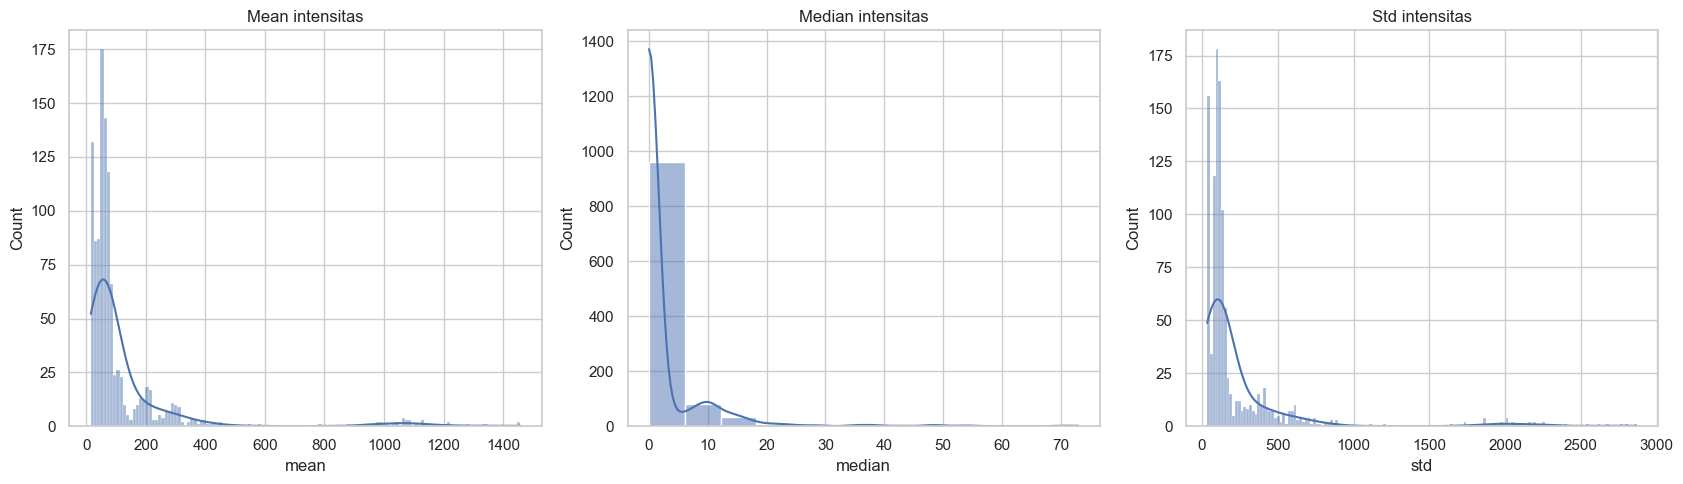

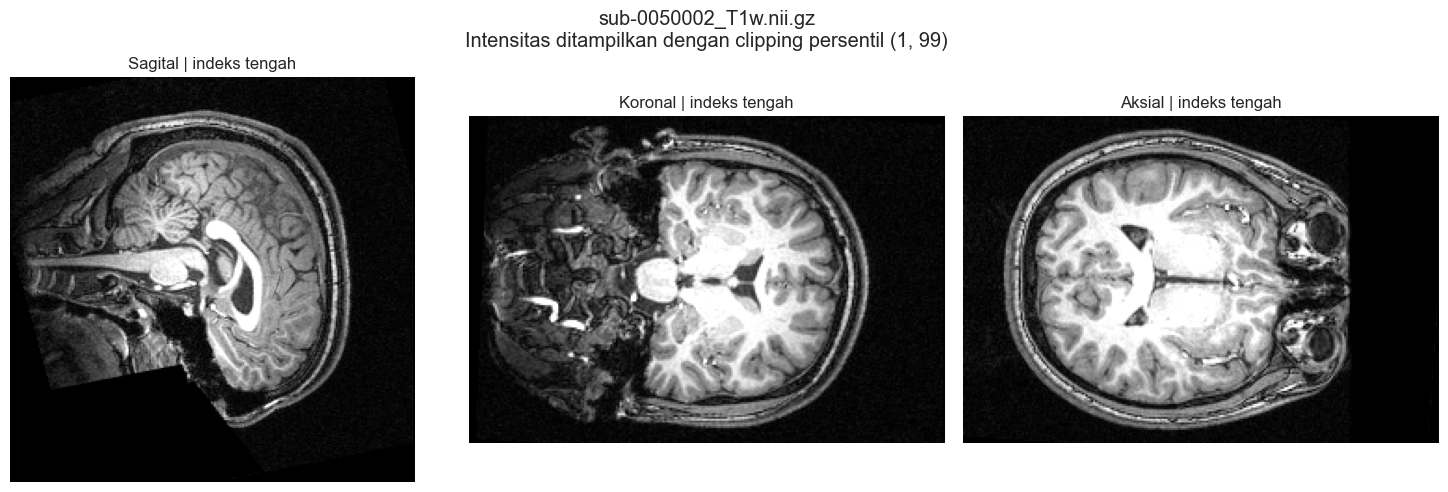

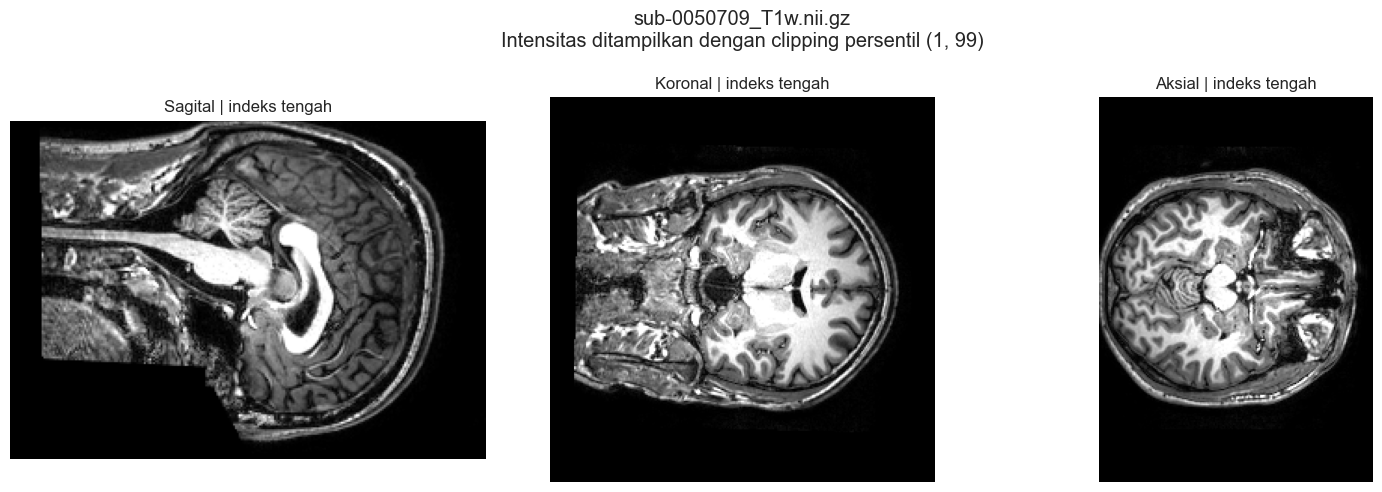

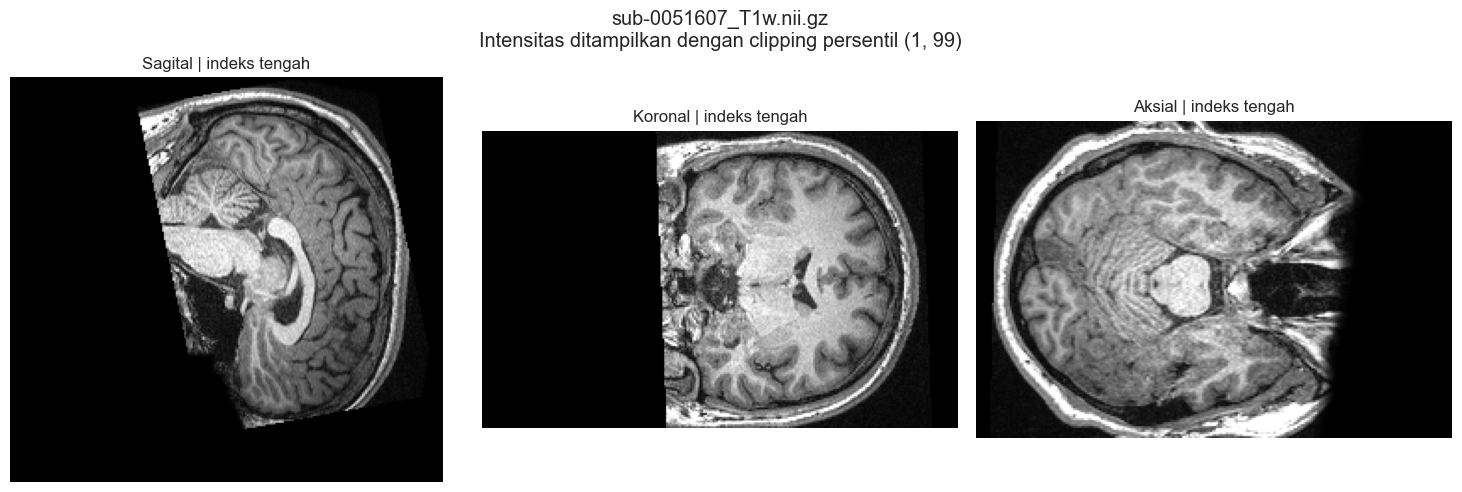

In [14]:
if not intensity_summary.empty:
    fig, axes = plt.subplots(1, 3, figsize=(17, 5))
    for column, title in [("mean", "Mean intensitas"), ("median", "Median intensitas"), ("std", "Std intensitas")]:
        if column in intensity_summary:
            sns.histplot(intensity_summary[column].dropna(), kde=True, ax=axes[["mean", "median", "std"].index(column)])
            axes[["mean", "median", "std"].index(column)].set_title(title)
            axes[["mean", "median", "std"].index(column)].set_xlabel(column)
    finish_figure()
else:
    print("Histogram tidak dibuat karena tidak ada ringkasan intensitas.")

valid_paths = [path for path in image_paths if path.name in loaded_images]
if valid_paths:
    sample_count = min(3, len(valid_paths))
    sample_paths = [valid_paths[int(i)] for i in np.linspace(0, len(valid_paths) - 1, sample_count)]
    for path in sample_paths:
        show_three_views(loaded_images[path.name], path.name)
else:
    print("Tidak ada citra valid untuk visualisasi.")

## 7. QC deskriptif: flagging only

Flag berikut tidak menghapus atau mengubah file: gagal dibaca, dimensi bukan 3D, volume kosong, voxel non-finite, dimensi/spasi yang jarang dibandingkan modus dataset, dan Subject ID yang tidak terdeteksi.

In [15]:
qc_columns = ["file_name", "subject_id", "read_ok", "error", "shape", "voxel_spacing", "voxel_count", "zero_fraction", "nonzero_voxel_count", "nonfinite_voxel_count"]
qc_flags = metadata_smri.reindex(columns=qc_columns).copy()
qc_flags["flag_read_error"] = ~qc_flags["read_ok"]
qc_flags["flag_not_3d"] = qc_flags["shape"].astype(str).str.count(",") < 2
qc_flags["flag_empty_volume"] = qc_flags["nonzero_voxel_count"].fillna(0).eq(0) & qc_flags["read_ok"]
qc_flags["flag_nonfinite"] = qc_flags["nonfinite_voxel_count"].fillna(0) > 0
qc_flags["flag_missing_subject_id"] = qc_flags["subject_id"].isna()
mode_shape = metadata_smri.loc[metadata_smri["read_ok"], "shape"].mode()
mode_spacing = metadata_smri.loc[metadata_smri["read_ok"], "voxel_spacing"].mode()
qc_flags["flag_rare_shape"] = metadata_smri["shape"].notna() & (metadata_smri["shape"] != (mode_shape.iloc[0] if len(mode_shape) else ""))
qc_flags["flag_rare_spacing"] = metadata_smri["voxel_spacing"].notna() & (metadata_smri["voxel_spacing"] != (mode_spacing.iloc[0] if len(mode_spacing) else ""))
flag_columns = [column for column in qc_flags.columns if column.startswith("flag_")]
qc_flags["any_flag"] = qc_flags[flag_columns].any(axis=1)
display(qc_flags)
print("Jumlah file dengan minimal satu flag:", int(qc_flags["any_flag"].sum()))

,file_name,subject_id,read_ok,error,shape,voxel_spacing,voxel_count,zero_fraction,nonzero_voxel_count,nonfinite_voxel_count,flag_read_error,flag_not_3d,flag_empty_volume,flag_nonfinite,flag_missing_subject_id,flag_rare_shape,flag_rare_spacing,any_flag
0,sub-0050002_T1w.nii.gz,sub-0050002,True,,"(176, 256, 256)","(np.float32(1.05), np.float32(1.05078), np.flo...",11534336,0.217022,9031135,0,False,False,False,False,False,True,True,True
1,sub-0050003_T1w.nii.gz,sub-0050003,True,,"(176, 256, 256)","(np.float32(1.05), np.float32(1.05078), np.flo...",11534336,0.250013,8650603,0,False,False,False,False,False,True,True,True
2,sub-0050004_T1w.nii.gz,sub-0050004,True,,"(176, 256, 256)","(np.float32(1.05), np.float32(1.05078), np.flo...",11534336,0.241141,8752931,0,False,False,False,False,False,True,True,True
3,sub-0050005_T1w.nii.gz,sub-0050005,True,,"(176, 256, 256)","(np.float32(1.05), np.float32(1.05078), np.flo...",11534336,0.247977,8674087,0,False,False,False,False,False,True,True,True
4,sub-0050006_T1w.nii.gz,sub-0050006,True,,"(176, 256, 256)","(np.float32(1.05), np.float32(1.05078), np.flo...",11534336,0.330776,7719060,0,False,False,False,False,False,True,True,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1097,sub-0051583_T1w.nii.gz,sub-0051583,True,,"(256, 256, 170)","(np.float32(1.0), np.float32(1.0), np.float32(...",11141120,0.664380,3739180,0,False,False,False,False,False,True,False,True
1098,sub-0051584_T1w.nii.gz,sub-0051584,True,,"(256, 256, 170)","(np.float32(1.0), np.float32(1.0), np.float32(...",11141120,0.691359,3438606,0,False,False,False,False,False,True,False,True
1099,sub-0051585_T1w.nii.gz,sub-0051585,True,,"(256, 256, 170)","(np.float32(1.0), np.float32(1.0), np.float32(...",11141120,0.686481,3492954,0,False,False,False,False,False,True,False,True
1100,sub-0051606_T1w.nii.gz,sub-0051606,True,,"(160, 240, 256)","(np.float32(1.0), np.float32(1.0), np.float32(...",9830400,0.542704,4495398,0,False,False,False,False,False,True,False,True


Jumlah file dengan minimal satu flag: 1102


## 8. Ringkasan akhir

Tabel berikut adalah pengganti export eksternal: seluruh ringkasan dapat disimpan bersama notebook melalui **Save/Save As** atau dijalankan ulang. Tidak ada keputusan final tentang kelayakan citra yang dibuat pada tahap EDA ini.

In [16]:
summary = pd.DataFrame({
    "metric": ["total_files", "readable_files", "read_error_files", "duplicate_names", "missing_subject_id", "files_with_any_qc_flag"],
    "value": [len(image_paths), int(metadata_smri["read_ok"].sum()) if not metadata_smri.empty else 0,
              int((~metadata_smri["read_ok"]).sum()) if not metadata_smri.empty else 0,
              int(inventory["file_name"].duplicated().sum()) if not inventory.empty else 0,
              int(inventory["subject_id"].isna().sum()) if not inventory.empty else 0,
              int(qc_flags["any_flag"].sum()) if not qc_flags.empty else 0],
})
display(summary)
print("\nInterpretasi dan keterbatasan:")
print("- Metadata dan statistik ini bersifat deskriptif; belum ada preprocessing citra.")
print("- Flag QC adalah daftar pemeriksaan untuk ditinjau, bukan keputusan menghapus file.")
print("- Indeks tengah pada visualisasi bukan penentuan posisi anatomis berbasis registrasi.")
print("- Perbedaan shape, spacing, orientasi, atau intensitas perlu ditinjau sebelum preprocessing.")
print("- Matching dengan CSV fenotipik dan pembentukan dataset final dilakukan pada tahap terpisah.")
print("- Hasil hanya tersimpan sebagai output cell notebook ini; tidak dibuat folder/file export.")

,metric,value
0,total_files,1102
1,readable_files,1102
2,read_error_files,0
3,duplicate_names,0
4,missing_subject_id,0
5,files_with_any_qc_flag,1102



Interpretasi dan keterbatasan:
- Metadata dan statistik ini bersifat deskriptif; belum ada preprocessing citra.
- Flag QC adalah daftar pemeriksaan untuk ditinjau, bukan keputusan menghapus file.
- Indeks tengah pada visualisasi bukan penentuan posisi anatomis berbasis registrasi.
- Perbedaan shape, spacing, orientasi, atau intensitas perlu ditinjau sebelum preprocessing.
- Matching dengan CSV fenotipik dan pembentukan dataset final dilakukan pada tahap terpisah.
- Hasil hanya tersimpan sebagai output cell notebook ini; tidak dibuat folder/file export.
